# Holdout y fuga transitiva
Fixture sintético; no evaluación de un predictor. Los grupos declarados no prueban identidad real.

In [1]:
import json
from pathlib import Path
from src.splitter import Record, components, split, leaked_components
print(json.loads(Path("results/summary.json").read_text()))

{'python': '3.12.14', 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39', 'results': {'row': {'leaked_total': 108, 'component_opportunities': 144, 'train_min': 18, 'train_max': 18, 'mean_ns': 384267.75, 'peak_bytes': 6724}, 'primary': {'leaked_total': 70, 'component_opportunities': 144, 'train_min': 17, 'train_max': 20, 'mean_ns': 353421.25, 'peak_bytes': 5120}, 'component': {'leaked_total': 0, 'component_opportunities': 144, 'train_min': 18, 'train_max': 18, 'mean_ns': 262558.9166666667, 'peak_bytes': 4104}}}


In [2]:
rows=[Record("a",("x",)),Record("b",("x","y")),Record("c",("y",)),Record("d",("z",))]
print(components(rows))
print(split(rows,"component"))

{'a': 'a', 'b': 'a', 'c': 'a', 'd': 'd'}
{'a': 'test', 'b': 'test', 'c': 'test', 'd': 'train'}


In [3]:
print("cortes:", leaked_components(rows,split(rows,"component")))
assert leaked_components(rows,split(rows,"component")) == 0

cortes: 0


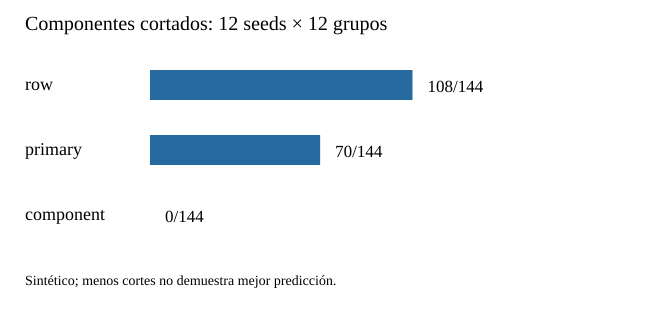

In [4]:
from IPython.display import SVG, display
display(SVG(filename="results/leakage.svg"))

Cero cortes se refiere al grafo provisto. No valida links, modelos, anonimización ni ausencia de fuga temporal. El criterio exige snapshot congelado.